# Palette automatique de couleurs : implémentation et analyse de la méthode ACoPa

**Projet 4IM01 – Télécom Paris, filière Imagerie – binôme : Aziz et Hugo**

Article étudié : J. Delon, A. Desolneux, J.-L. Lisani, A.-B. Petro, *Automatic Color Palette*, Inverse Problems and Imaging 1(2), 2007, p. 265-287.

Ce notebook sert de rapport. Il contient la présentation des méthodes, le code qui produit toutes les figures, les expériences, une analyse critique et la description de notre usage des agents conversationnels. Le code des méthodes est dans les fichiers `.py` du dépôt (voir le `README.md`, qui précise aussi qui a écrit chaque fichier).

**Plan**
1. Le problème : réduire une image à quelques couleurs
2. Méthodes classiques et leur limite
3. La méthode ACoPa : histogrammes, test d'unimodalité, algorithme FTC
4. Expériences
5. Analyse critique
6. Utilisation des agents conversationnels
7. Répartition du travail et références

## 1. Le problème

Une image couleur 8 bits peut contenir jusqu'à $256^3 \approx 16{,}7$ millions de couleurs. `Poivrons.jpeg` ($512\times512$) en contient plusieurs dizaines de milliers. On cherche une **palette** : un petit ensemble de $K$ couleurs qui suffit à représenter l'image, chaque pixel étant remplacé par la couleur de la palette la plus proche. Cela sert à la compression, à l'affichage avec peu de couleurs, à la description d'une image (« rouge, vert, jaune ») ou au rendu « cartoon ».

Deux questions se posent :
- **combien** de couleurs garder ($K$) ;
- **lesquelles** garder, en particulier quand une couleur vive n'occupe qu'une petite zone de l'image.

Les méthodes classiques demandent $K$ à l'utilisateur et cherchent surtout à minimiser l'erreur moyenne. L'article propose une méthode, **ACoPa**, qui trouve $K$ toute seule et garde les petites zones de couleur, grâce à une analyse statistique des histogrammes de teinte, de saturation et d'intensité.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.color import rgb2lab, deltaE_cie76

import median_cut, popularite, kmeans_rapide
import segmentation_naive as naive
import segmentation_auto as auto

plt.rcParams["figure.dpi"] = 80


def charger(chemin):
    return np.array(Image.open(chemin).convert("RGB"))


def mesures(image, quantifiee, masque=None):
    # MSE et PSNR calculés sur RGB, et écart de couleur dE (CIE76) dans l'espace Lab,
    # qui est plus proche de ce que voit l'oeil. dE < 2-3 : différence à peine visible.
    mse = ((image.astype(float) - quantifiee.astype(float)) ** 2).mean()
    psnr = 10 * np.log10(255 ** 2 / mse)
    dE = deltaE_cie76(rgb2lab(image / 255), rgb2lab(quantifiee / 255))
    ligne = [mse, psnr, dE.mean()]
    if masque is not None:
        ligne.append(dE[masque].mean())  # erreur sur une petite zone de couleur choisie
    return ligne


def methodes_classiques(image, K):
    resultats = {}
    resultats["Popularité"] = popularite.remplacer_par_palette(image, popularite.popularite(image, K))
    resultats["Median cut"] = median_cut.remap(image, median_cut.median_cut(image, K))
    centres, labels = kmeans_rapide.kmeans(image, kmeans_rapide.centres_aleatoires(image, K), afficher=False)
    resultats["K-means (hasard)"] = kmeans_rapide.image_depuis_labels(centres, labels)
    return resultats


def afficher_tableau(image, resultats, masque=None):
    entete = f"{'Méthode':26s}{'MSE':>9s}{'PSNR (dB)':>11s}{'dE moyen':>10s}"
    if masque is not None:
        entete += f"{'dE petite zone':>16s}"
    print(entete)
    for nom, q in resultats.items():
        valeurs = mesures(image, q, masque)
        ligne = f"{nom:26s}{valeurs[0]:9.1f}{valeurs[1]:11.2f}{valeurs[2]:10.2f}"
        if masque is not None:
            ligne += f"{valeurs[3]:16.2f}"
        print(ligne)


def afficher_grille(images, titres, ncol=3, taille=3.3):
    nlig = int(np.ceil(len(images) / ncol))
    fig, axes = plt.subplots(nlig, ncol, figsize=(taille * ncol, taille * nlig))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, im, t in zip(np.ravel(axes), images, titres):
        ax.imshow(im)
        ax.set_title(t, fontsize=9)
    plt.tight_layout()
    plt.show()


poivrons = charger("images/Poivrons.jpeg")
fleur = charger("images/fleur.tif")
for nom, im in [("Poivrons", poivrons), ("Fleur", fleur)]:
    print(f"{nom} : {im.shape[1]}x{im.shape[0]} pixels, {len(np.unique(im.reshape(-1, 3), axis=0))} couleurs distinctes")

Poivrons : 512x512 pixels, 86757 couleurs distinctes


Fleur : 604x562 pixels, 157458 couleurs distinctes


## 2. Méthodes classiques et leur limite

Nous avons commencé le projet par ces méthodes, pour prendre en main le problème. Les premiers essais de K-means « à la main », avec une double boucle sur les pixels, sont conservés dans `apprentissage/`.

**Popularité.** On regroupe les couleurs proches dans des cases (on garde les 4 bits de poids fort de chaque canal, soit $16^3$ cases), puis on garde les $K$ cases qui contiennent le plus de pixels. *Exemple :* sur les poivrons, les cases rouges et vertes sont très remplies et sont gardées. Une petite zone jaune n'est jamais parmi les $K$ plus remplies.

**Median cut** (Heckbert, 1982). On part d'une boîte qui contient tous les pixels dans le cube RGB. On coupe la boîte choisie en deux à la médiane, selon l'axe où elle est la plus étendue, et on recommence jusqu'à avoir $K$ boîtes. La couleur de chaque boîte est la moyenne de ses pixels. *Exemple :* pour $K=2$, la première coupe sépare souvent les pixels sombres des pixels clairs, car c'est la direction où le nuage est le plus étalé.

**K-means.** On cherche $K$ centres $c_1,\dots,c_K$ qui minimisent $\sum_{p}\min_k \lVert x_p - c_k\rVert^2$. On alterne deux étapes : chaque pixel va vers son centre le plus proche, puis chaque centre devient la moyenne de ses pixels. Le résultat dépend des centres de départ. *Exemple :* nos premiers essais avec des centres « rouge pur, vert pur… » qui n'existent pas dans l'image donnaient une image presque entièrement marron.

Ces trois méthodes ont deux défauts : **$K$ est fixé à la main**, et elles favorisent les couleurs **fréquentes**, puisque le critère est une erreur moyenne sur tous les pixels.

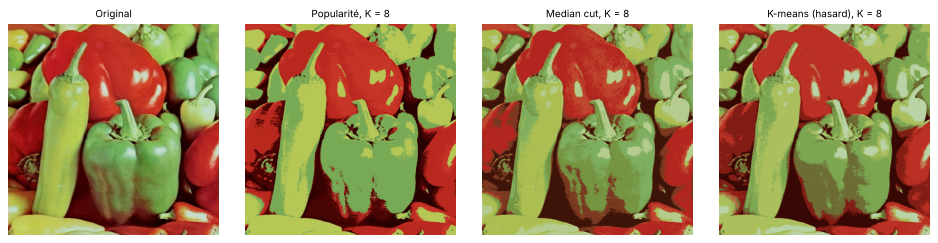

Méthode                         MSE  PSNR (dB)  dE moyen
Popularité                    596.3      20.38     14.39
Median cut                    275.9      23.72     11.61
K-means (hasard)              220.7      24.69     10.34


In [2]:
K = 8
resultats = methodes_classiques(poivrons, K)
afficher_grille([poivrons] + list(resultats.values()), ["Original"] + [f"{n}, K = {K}" for n in resultats], ncol=4, taille=3)
afficher_tableau(poivrons, resultats)

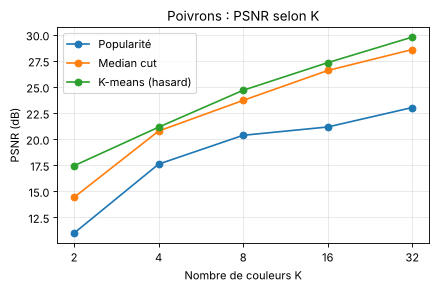

In [3]:
# Erreur en fonction de K (même calcul que comparaison.py, avec moins de valeurs de K)
valeurs_K = [2, 4, 8, 16, 32]
psnr = {}
for K in valeurs_K:
    for nom, q in methodes_classiques(poivrons, K).items():
        psnr.setdefault(nom, []).append(mesures(poivrons, q)[1])
plt.figure(figsize=(6, 3.5))
for nom, v in psnr.items():
    plt.plot(valeurs_K, v, marker="o", label=nom)
plt.xscale("log", base=2)
plt.xticks(valeurs_K, valeurs_K)
plt.xlabel("Nombre de couleurs K")
plt.ylabel("PSNR (dB)")
plt.grid(alpha=0.3)
plt.legend()
plt.title("Poivrons : PSNR selon K")
plt.show()

**Observations.** K-means donne la meilleure erreur, ce qui est logique puisqu'il minimise justement l'erreur quadratique. Le median cut le suit de près, la popularité est nettement moins bonne. Aucune méthode ne dit **quel $K$ choisir** : la courbe monte régulièrement, sans « coude » net. On verra au §4.1 que, même avec un bon PSNR, une petite zone de couleur vive peut disparaître complètement. C'est ce qui motive la segmentation d'histogrammes.

## 3. La méthode ACoPa

### 3.1 Espace HSI et cylindre des gris

L'article travaille dans l'espace teinte–saturation–intensité, car la teinte est la composante la plus discriminante pour l'oeil et elle dépend peu de l'éclairage :

$$I=\frac{R+G+B}{3},\qquad S=\sqrt{(R-I)^2+(G-I)^2+(B-I)^2},\qquad H=\arccos\frac{(G-I)-(B-I)}{S\sqrt2}.$$

$S$ est la distance à l'axe des gris et $H$ l'angle autour de cet axe. La formule en $\arccos$ ne donne qu'un angle dans $[0^\circ,180^\circ]$. Nous utilisons $\operatorname{arctan2}$, qui donne le même angle sur le cercle entier (rouge $=0^\circ$, vert $=120^\circ$, bleu $=240^\circ$). L'histogramme de teinte est **circulaire** : $359^\circ$ est voisin de $0^\circ$.

Pour un pixel presque gris, la teinte n'a pas de sens. L'article donne un argument simple : à distance $S$ de l'axe des gris, il y a au plus $2\pi S$ couleurs sur le cercle. Pour découper la teinte en $Q$ classes, il faut donc $S > \frac{Q}{2\pi}$. Les pixels tels que $S\le\frac{Q}{2\pi}$ forment le **cylindre des gris**. *Exemple :* pour $Q=360$, le seuil vaut $57{,}3$. Le gris $(128,128,128)$ a $S=0$ et est exclu de l'histogramme de teinte. Le rouge pur $(255,0,0)$ a $S\approx208$ et y est compté.

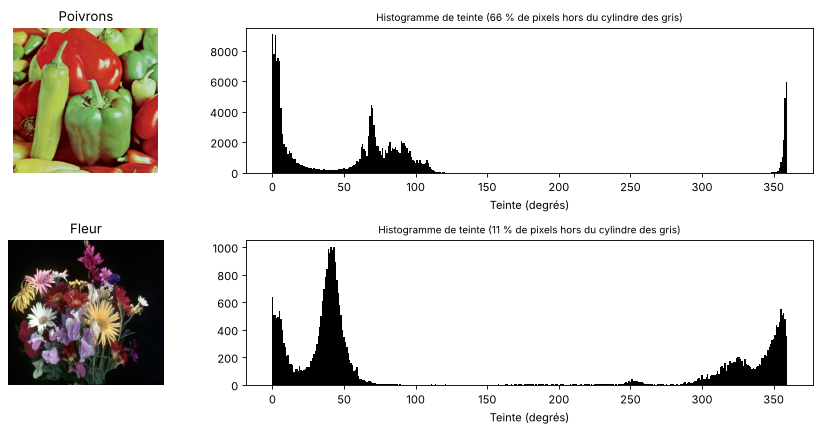

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.5), gridspec_kw={"width_ratios": [1, 2.2]})
for ligne, (nom, im) in enumerate([("Poivrons", poivrons), ("Fleur", fleur)]):
    H, S, I = naive.rgb_vers_hsi(im)
    colores = naive.pixels_colores(S)
    h = np.bincount(np.floor(H[colores]).astype(int) % 360, minlength=360)
    axes[ligne, 0].imshow(im)
    axes[ligne, 0].axis("off")
    axes[ligne, 0].set_title(nom)
    axes[ligne, 1].bar(np.arange(360), h, width=1, color="black")
    axes[ligne, 1].set_title(f"Histogramme de teinte ({100 * colores.mean():.0f} % de pixels hors du cylindre des gris)", fontsize=9)
    axes[ligne, 1].set_xlabel("Teinte (degrés)")
plt.tight_layout()
plt.show()

Pour les poivrons, on voit un mode rouge à cheval sur $0^\circ$ (d'où l'importance de la circularité), puis des modes jaune et vert entre $50^\circ$ et $110^\circ$. Pour la fleur, $89\,\%$ des pixels sont dans le cylindre des gris (fond noir). Les teintes rouges et roses, jaunes et violettes forment des modes de tailles très différentes. Le petit mode violet vers $250^\circ$ correspond à quelques petites fleurs : c'est l'équivalent de la « coccinelle » de l'article.

### 3.2 Croissant, décroissant : l'estimateur de Grenander

Pour décider si un morceau d'histogramme $h=(h_1,\dots,h_L)$ est « une seule bosse », on le compare à la meilleure approximation **décroissante** (ou croissante) de $h$. C'est l'estimateur de Grenander, que l'on calcule avec l'algorithme **Pool Adjacent Violators** (annexe B de l'article) : tant que deux valeurs successives violent la décroissance, on les remplace par leur moyenne.

*Exemple :* $h=(5,3,4,2)$. Le couple $(3,4)$ viole la décroissance, on le remplace par $(3{,}5;\,3{,}5)$ et on obtient $(5;\,3{,}5;\,3{,}5;\,2)$, qui est décroissant et a la même masse.

Un morceau est **unimodal** sur $[a,b]$ s'il existe un pic $c$ tel que $h$ est « croissant » sur $[a,c]$ et « décroissant » sur $[c,b]$. Tout le problème est de donner un sens précis à « est croissant », car un histogramme réel n'est jamais exactement monotone à cause du bruit.

### 3.3 Version naïve : un seuil réglé à la main (`segmentation_naive.py`)

Notre première idée a été de mesurer la part des pixels qu'il faut déplacer pour passer de $h$ à son approximation croissante–décroissante $\hat h$ autour du pic $c$ :

$$d(h)=\frac{1}{2N}\sum_{i}\lvert h_i-\hat h_i\rvert,\qquad N=\sum_i h_i,$$

et de déclarer $h$ unimodal si $d(h)\le\texttt{SEUIL}$. *Exemple :* avec $\texttt{SEUIL}=0{,}05$, un morceau est unimodal s'il suffit de déplacer au plus $5\,\%$ de ses pixels pour le rendre croissant puis décroissant.

Ce critère ne tient pas compte de $N$. Or un écart de $1\,\%$ sur $200\,000$ pixels ($2\,000$ pixels) ne peut pas être dû au hasard, alors qu'un écart de $1\,\%$ sur $100$ pixels ($1$ pixel) l'est sûrement.

Petite bosse : 74 pixels sur 12606
Test                           deux bosses   une bosse bruitée
naïf, SEUIL = 0.05                       1                   1
naïf, SEUIL = 0.01                       1                   1
naïf, SEUIL = 0.003                      2                   1
a contrario, epsilon = 1                 2                   1


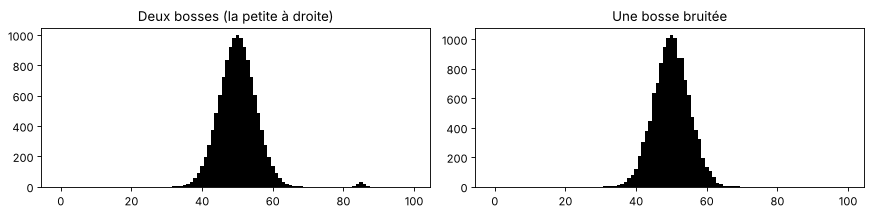

In [5]:
# Une grosse bosse (environ 12 500 pixels) et une petite bosse séparée (74 pixels)
x = np.arange(100)
grosse = np.round(1000 * np.exp(-(x - 50) ** 2 / 50))
petite = np.round(30 * np.exp(-(x - 85) ** 2 / 2))
h = grosse + petite
bruitee = np.random.default_rng(1).poisson(grosse)  # une seule bosse, avec du bruit de comptage

print(f"Petite bosse : {petite.sum():.0f} pixels sur {h.sum():.0f}")
print(f"{'Test':28s}{'deux bosses':>14s}{'une bosse bruitée':>20s}")
for seuil in [0.05, 0.01, 0.003]:
    test = lambda g, s=seuil: naive.est_unimodal_naif(g, s)
    print(f"{'naïf, SEUIL = ' + str(seuil):28s}{len(naive.ftc(h, test)) - 1:>14d}{len(naive.ftc(bruitee, test)) - 1:>20d}")
print(f"{'a contrario, epsilon = 1':28s}{len(naive.ftc(h, auto.est_unimodal_auto)) - 1:>14d}{len(naive.ftc(bruitee, auto.est_unimodal_auto)) - 1:>20d}")

fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
ax[0].bar(x, h, width=1, color="black"); ax[0].set_title("Deux bosses (la petite à droite)")
ax[1].bar(x, bruitee, width=1, color="black"); ax[1].set_title("Une bosse bruitée")
plt.tight_layout(); plt.show()

Avec le seuil naïf, il faut descendre à $\texttt{SEUIL}=0{,}003$ pour voir la petite bosse, et ce réglage n'est bon que pour cet histogramme précis. Le §4.3 montre que, sur de vraies images, le nombre de couleurs passe brutalement de quelques centaines à 2 ou 3 quand on change le seuil. Le test a contrario, lui, trouve les deux bosses sans réglage et ne coupe pas la bosse bruitée.

### 3.4 Version automatique : le test a contrario (`segmentation_auto.py`)

L'article utilise un test multiple introduit par Desolneux, Moisan et Morel et adapté aux histogrammes dans la référence [10] de l'article (Delon et al., IEEE TIP 2007). Soit $h$ un histogramme de $N$ pixels et $p$ une loi de référence, ici l'estimateur de Grenander normalisé. Pour un intervalle $[a,b]$, on note $r(a,b)$ la proportion observée de pixels dans $[a,b]$ et $p(a,b)$ la proportion attendue. Si $h$ suit la loi $p$, le nombre de pixels dans $[a,b]$ suit une loi binomiale $\mathcal B(N,p(a,b))$. La probabilité d'un écart au moins aussi grand que celui observé est majorée (borne de Hoeffding) par $e^{-N\,\mathcal H(r,p)}$, avec l'entropie relative

$$\mathcal H(r,p)=r\log\frac rp+(1-r)\log\frac{1-r}{1-p}.$$

On teste **tous** les intervalles, soit $\frac{L(L+1)}{2}$ tests, et on définit le **nombre de fausses alarmes**

$$\mathrm{NFA}([a,b])=\frac{L(L+1)}{2}\,e^{-N\,\mathcal H(r(a,b),\,p(a,b))}.$$

L'hypothèse « $h$ suit $p$ » est rejetée si un intervalle vérifie $\mathrm{NFA}<\varepsilon$, c'est-à-dire $\mathcal H(r,p)>\frac1N\log\frac{L(L+1)}{2\varepsilon}$. Le seuil **dépend de $N$**, ce qui corrige le défaut de la version naïve. Le paramètre $\varepsilon$ a un sens concret : c'est le nombre moyen de fausses détections que l'on accepte sur un histogramme qui suit vraiment $p$. On prend $\varepsilon=1$, comme dans [10].

*Exemple :* pour un morceau de $L=360$ classes et $N=10\,000$ pixels, on rejette dès que $\mathcal H>\log(64\,980)/10\,000\approx1{,}1\times10^{-3}$. Avec $N=100$ pixels, il faut $\mathcal H>0{,}11$, soit un écart cent fois plus grand.

**Simplifications de notre implémentation**
- Nous utilisons la borne de Hoeffding plutôt que la queue binomiale exacte. Nous n'avons pas pu vérifier dans [10] laquelle des deux formes est utilisée exactement.
- Pour le pic $c$, nous essayons seulement les 3 classes les plus hautes du morceau. L'article demande qu'il existe un $c$, ce qui reviendrait à tous les tester.
- $L$ est fixé à 360 pour tous les histogrammes.

### 3.5 L'algorithme FTC (Fine To Coarse)

1. On part de la segmentation la plus fine : tous les minima locaux de $h$, plus les deux extrémités.
2. On choisit au hasard deux morceaux voisins. Si leur union est unimodale, on les fusionne. On s'arrête quand plus aucune paire ne peut être fusionnée.
3. On recommence avec des unions de $j=3,4,\dots$ morceaux voisins. Notre variante : après une fusion à $j\ge3$, nous revenons à $j=2$, pour que la segmentation finale soit bien « admissible » au sens de l'article (aucune union de morceaux voisins n'est unimodale).

**Circularité de la teinte.** On coupe le cercle à la classe où l'histogramme est le plus bas, on fait tourner l'histogramme pour qu'elle soit au début, et on applique le FTC classique. C'est notre choix : l'article dit seulement que les modes peuvent être circulaires.

### 3.6 Hiérarchie teinte → saturation → intensité

1. On applique le FTC à l'histogramme de teinte des pixels hors du cylindre des gris.
2. Tous les pixels, y compris les gris, sont rattachés à un mode de teinte selon leur teinte.
3. Pour chaque mode de teinte, on applique le FTC à l'histogramme de saturation de ses pixels.
4. Pour chaque mode (teinte, saturation), on applique le FTC à l'histogramme d'intensité.

Chaque groupe final donne une couleur : la moyenne RGB de ses pixels. Ces couleurs servent de **graines** à K-means (annexe A), en RGB ou en CIE Lab. Le nombre de couleurs $K$ est donc fixé par les données.

Fleur : 5 modes de teinte, 9 après la saturation, 17 couleurs au total (0.2 s)


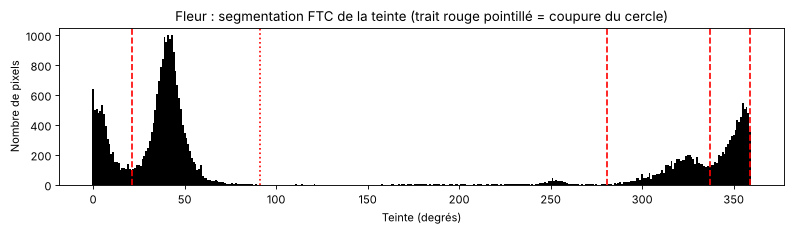

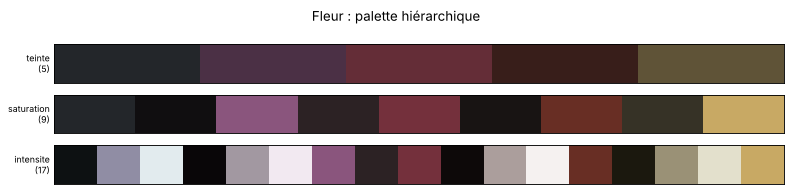

Poivrons : 9 modes de teinte, 20 après la saturation, 39 couleurs au total (0.2 s)


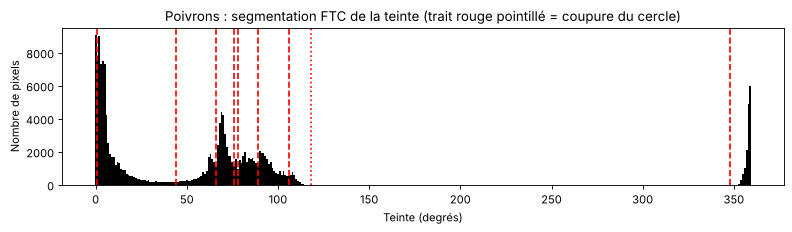

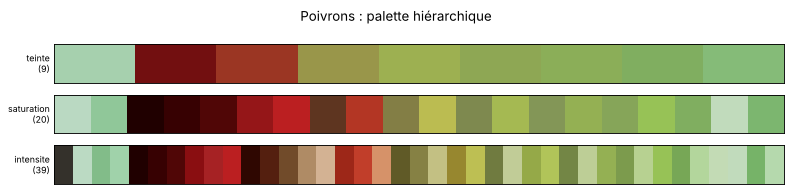

In [6]:
for nom, im in [("Fleur", fleur), ("Poivrons", poivrons)]:
    debut = time.time()
    graines, effectifs, niveaux, infos = naive.palette_acopa(im, auto.est_unimodal_auto, afficher=False)
    print(f"{nom} : {len(niveaux['teinte'])} modes de teinte, {len(niveaux['saturation'])} après la saturation, "
          f"{len(graines)} couleurs au total ({time.time() - debut:.1f} s)")
    naive.afficher_segmentation_teinte(infos["h_teinte"], infos["bornes_H"], infos["decalage"],
                                       f"{nom} : segmentation FTC de la teinte (trait rouge pointillé = coupure du cercle)")
    plt.show()
    naive.afficher_palette_hierarchique(niveaux, f"{nom} : palette hiérarchique")
    plt.show()

La palette hiérarchique reproduit la figure 4(e) de l'article : chaque ligne est un niveau de la hiérarchie, et le nombre de couleurs augmente quand on ajoute la saturation puis l'intensité. Pour la fleur, on obtient 5 modes de teinte et 17 couleurs. Les violets, roses et jaunes, qui occupent peu de pixels, ont chacun leur couleur.

Pour les poivrons, on obtient 9 modes de teinte, ce qui est plus que ce que l'on voit à l'oeil (rouge, jaune, vert), et 39 couleurs. Le §5 revient sur ce point.

## 4. Expériences

Comme dans l'article, nous comparons ACoPa + K-means (RGB et Lab) aux méthodes classiques **avec le même nombre de couleurs** $K$, celui trouvé par ACoPa. En plus du MSE et du PSNR, nous mesurons l'écart de couleur $\Delta E$ dans l'espace Lab, en moyenne sur l'image et en moyenne **sur une petite zone de couleur** choisie à l'avance. C'est notre ajout pour quantifier la conservation des petits détails, que l'article montre seulement visuellement.

### 4.1 Image synthétique « coccinelle »

Fond vert texturé et bruité, avec un petit disque rouge qui occupe $0{,}7\,\%$ de l'image.

ACoPa trouve K = 3 couleurs ; disque rouge = 0.7 % des pixels


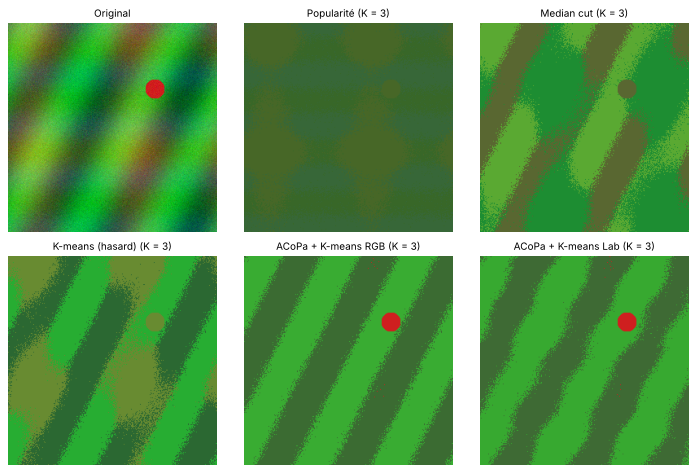

Méthode                         MSE  PSNR (dB)  dE moyen  dE petite zone
Popularité                   1311.2      16.95     29.14           90.67
Median cut                    524.4      20.93     17.56           82.65
K-means (hasard)              500.8      21.13     16.14           93.17
ACoPa + K-means RGB           625.9      20.17     15.47            4.77
ACoPa + K-means Lab           641.3      20.06     15.09            4.77


In [7]:
rng = np.random.default_rng(0)
y, x = np.mgrid[0:256, 0:256]
fond = np.stack([60 + 40 * np.sin(x / 20) + 30 * np.cos(y / 25),
                 140 + 50 * np.sin(x / 15 + y / 30),
                 50 + 20 * np.cos(y / 10)], axis=-1)
fond += rng.normal(0, 10, fond.shape)
disque = (x - 180) ** 2 + (y - 80) ** 2 < 12 ** 2
fond[disque] = np.array([210, 30, 30]) + rng.normal(0, 8, (disque.sum(), 3))
coccinelle = np.clip(fond, 0, 255).astype(np.uint8)

res_lab, palette, graines, niveaux, infos = auto.acopa_complet(coccinelle, "Lab", afficher=False)
res_rgb, _ = auto.acopa_kmeans(coccinelle, graines, "RGB")
K = len(palette)
resultats = methodes_classiques(coccinelle, K)
resultats["ACoPa + K-means RGB"] = res_rgb
resultats["ACoPa + K-means Lab"] = res_lab
print(f"ACoPa trouve K = {K} couleurs ; disque rouge = {100 * disque.mean():.1f} % des pixels")
afficher_grille([coccinelle] + list(resultats.values()), ["Original"] + [f"{n} (K = {K})" for n in resultats], ncol=3, taille=3)
afficher_tableau(coccinelle, resultats, masque=disque)

C'est le résultat central du projet. Avec $K=3$, les trois méthodes classiques dépensent leurs couleurs sur les nuances du fond vert, et le disque rouge disparaît : $\Delta E$ sur le disque entre 80 et 95, c'est-à-dire qu'il devient vert. ACoPa détecte le petit mode rouge dans l'histogramme de teinte et le garde : $\Delta E\approx5$ sur le disque.

En contrepartie, son MSE global est un peu moins bon que celui de K-means, car une des 3 couleurs est « réservée » à $0{,}7\,\%$ des pixels. Le MSE et le PSNR ne mesurent donc pas ce que l'on cherche ici.

### 4.2 Images réelles

Fleur : K = 17 (ACoPa + K-means Lab en 2.3 s), petite zone violette = 524 pixels


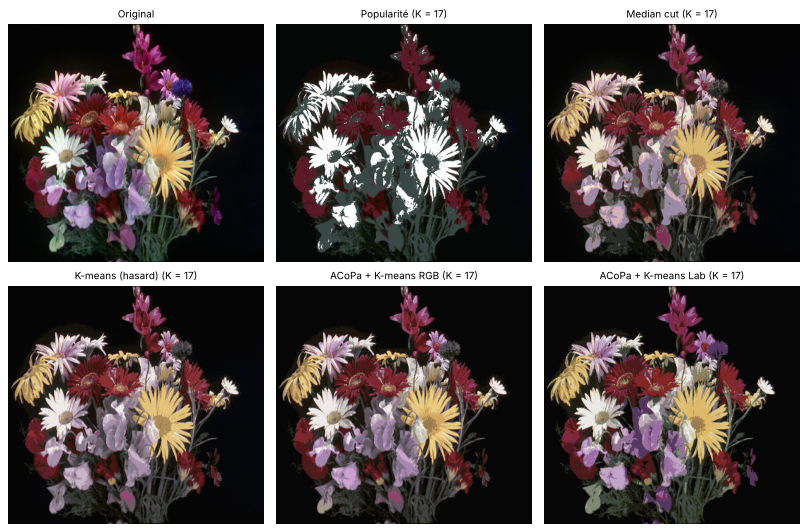

Méthode                         MSE  PSNR (dB)  dE moyen  dE petite zone
Popularité                   1197.2      17.35     12.46           59.22
Median cut                    179.8      25.58      8.45           50.73
K-means (hasard)              131.6      26.94      7.74           47.42
ACoPa + K-means RGB           126.3      27.12      7.50           45.08


ACoPa + K-means Lab           204.9      25.02      6.45           28.11


Poivrons : K = 39 (ACoPa + K-means Lab en 3.3 s), petite zone violette = 0 pixels


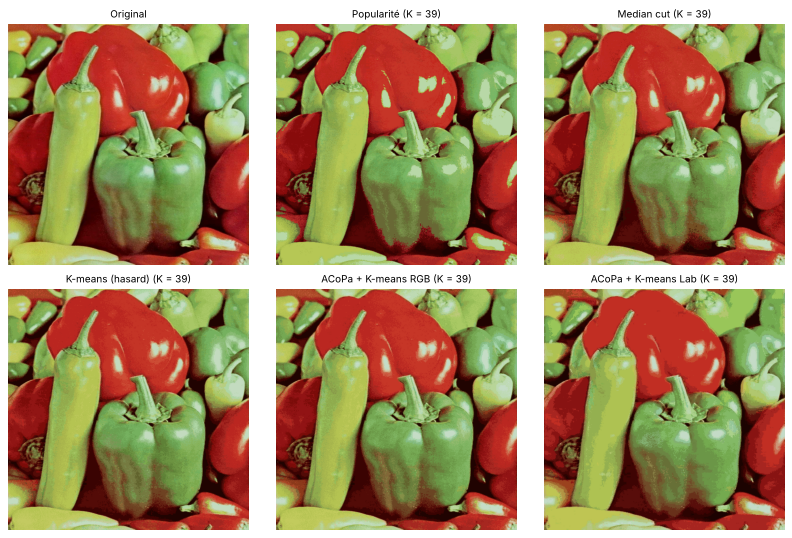

Méthode                         MSE  PSNR (dB)  dE moyen
Popularité                    141.3      26.63      7.68
Median cut                     75.4      29.36      6.57
K-means (hasard)               60.2      30.34      5.92
ACoPa + K-means RGB            60.0      30.35      5.95
ACoPa + K-means Lab           105.2      27.91      5.18


In [8]:
for nom, im in [("Fleur", fleur), ("Poivrons", poivrons)]:
    H, S, I = naive.rgb_vers_hsi(im)
    # Petite zone : pixels violets (teinte entre 220 et 280 degrés, hors du cylindre des gris)
    masque = naive.pixels_colores(S) & (H > 220) & (H < 280)
    debut = time.time()
    res_lab, palette, graines, niveaux, infos = auto.acopa_complet(im, "Lab", afficher=False)
    duree = time.time() - debut
    res_rgb, _ = auto.acopa_kmeans(im, graines, "RGB")
    K = len(palette)
    resultats = methodes_classiques(im, K)
    resultats["ACoPa + K-means RGB"] = res_rgb
    resultats["ACoPa + K-means Lab"] = res_lab
    print(f"{nom} : K = {K} (ACoPa + K-means Lab en {duree:.1f} s), petite zone violette = {masque.sum()} pixels")
    afficher_grille([im] + list(resultats.values()), ["Original"] + [f"{n} (K = {K})" for n in resultats], ncol=3, taille=3.4)
    afficher_tableau(im, resultats, masque if masque.sum() > 0 else None)

**Fleur ($K=17$).** ACoPa + K-means RGB a la meilleure erreur quadratique, devant K-means au hasard. En Lab, le PSNR est moins bon, mais le $\Delta E$ moyen est le meilleur, et surtout l'erreur sur les fleurs violettes tombe à $\Delta E\approx28$ contre 45 à 60 pour les autres méthodes. C'est la même conclusion que l'article : **l'espace Lab représente mieux les petites zones de couleur**, au prix d'une erreur RGB un peu plus grande.

**Poivrons ($K=39$).** Les méthodes ont des PSNR proches : ACoPa RGB et K-means sont autour de 30 dB. Comme il n'y a pas de petite zone de couleur isolée dans cette image, l'avantage d'ACoPa porte surtout sur le choix automatique de $K$. Le résultat en Lab a encore le meilleur $\Delta E$ moyen.

### 4.3 Sensibilité aux paramètres

In [9]:
def nombre_de_couleurs(im, test, **options):
    graines, _, niveaux, _ = naive.palette_acopa(im, test, afficher=False, **options)
    return len(niveaux["teinte"]), len(graines)

print("Version naïve : nombre de couleurs selon SEUIL (teinte / total)")
for seuil in [0.01, 0.02, 0.05, 0.1]:
    test = lambda g, s=seuil: naive.est_unimodal_naif(g, s)
    print(f"  SEUIL = {seuil:<5}  Fleur : {nombre_de_couleurs(fleur, test)}   Poivrons : {nombre_de_couleurs(poivrons, test)}")

print("\nVersion a contrario : nombre de couleurs selon epsilon (teinte / total)")
for eps in [1e-4, 1e-2, 1, 1e2, 1e4]:
    auto.EPSILON = eps
    print(f"  epsilon = {eps:<7g}  Fleur : {nombre_de_couleurs(fleur, auto.est_unimodal_auto)}   Poivrons : {nombre_de_couleurs(poivrons, auto.est_unimodal_auto)}")
auto.EPSILON = 1.0

print("\nVersion a contrario : selon la largeur des classes de S et I (teinte / total)")
for largeur in [1, 2, 4, 6]:
    print(f"  largeur = {largeur}  Fleur : {nombre_de_couleurs(fleur, auto.est_unimodal_auto, largeur=largeur)}   "
          f"Poivrons : {nombre_de_couleurs(poivrons, auto.est_unimodal_auto, largeur=largeur)}")

Version naïve : nombre de couleurs selon SEUIL (teinte / total)


  SEUIL = 0.01   Fleur : (64, 1475)   Poivrons : (10, 74)


  SEUIL = 0.02   Fleur : (56, 657)   Poivrons : (5, 18)
  SEUIL = 0.05   Fleur : (2, 3)   Poivrons : (2, 4)


  SEUIL = 0.1    Fleur : (2, 2)   Poivrons : (2, 2)

Version a contrario : nombre de couleurs selon epsilon (teinte / total)


  epsilon = 0.0001   Fleur : (4, 11)   Poivrons : (8, 35)


  epsilon = 0.01     Fleur : (5, 15)   Poivrons : (8, 37)


... (3 outputs left out)

  largeur = 1  Fleur : (5, 28)   Poivrons : (9, 181)


  largeur = 2  Fleur : (5, 16)   Poivrons : (9, 58)


  largeur = 4  Fleur : (5, 17)   Poivrons : (9, 39)


  largeur = 6  Fleur : (5, 15)   Poivrons : (9, 34)


In [10]:
# Influence de l'ordre aléatoire des fusions dans le FTC (graine du tirage au hasard)
ftc_original = naive.ftc
for nom, im in [("Fleur", fleur), ("Poivrons", poivrons)]:
    nombres = []
    for graine in range(5):
        naive.ftc = lambda h, test, graine_ignoree=0, g=graine: ftc_original(h, test, g)
        nombres.append(len(naive.palette_acopa(im, auto.est_unimodal_auto, afficher=False)[0]))
    naive.ftc = ftc_original
    print(f"{nom} : nombre de couleurs pour 5 ordres de fusion différents : {nombres}")

Fleur : nombre de couleurs pour 5 ordres de fusion différents : [17, 15, 18, 16, 17]


Poivrons : nombre de couleurs pour 5 ordres de fusion différents : [39, 41, 39, 40, 37]


**Ce que montrent ces tableaux**
- **Version naïve :** le nombre de couleurs dépend énormément du seuil. Pour la fleur, il passe de plusieurs centaines (seuil 0,02) à 3 (seuil 0,05), et aucune valeur ne convient aux deux images. Le seuil est en fraction des pixels, donc il est trop sévère pour les petits histogrammes et trop laxiste pour les grands.
- **Version a contrario :** quand $\varepsilon$ varie de $10^{-4}$ à $10^{2}$ (six ordres de grandeur), $K$ ne varie que de 11 à 19 pour la fleur et de 35 à 60 pour les poivrons. Comme $\varepsilon$ n'intervient qu'à travers $\log\varepsilon$, il n'y a **pratiquement pas de paramètre à régler**, ce qui est l'argument principal de l'article.
- **Largeur des classes de S et I :** avec des classes de largeur 1, les poivrons donnent 181 couleurs. Les histogrammes de saturation sont « en peigne », parce que les valeurs RGB de cette image sont irrégulièrement remplies (certaines valeurs sont deux fois plus fréquentes que leurs voisines). Le test a contrario, très puissant quand $N$ est grand, voit ces dents comme de vrais modes. Nous avons choisi une largeur de 4 par défaut. Ce paramètre n'est pas discuté dans l'article.
- **Ordre des fusions :** le résultat varie de $\pm2$ couleurs selon l'ordre aléatoire des fusions. C'est faible, mais la méthode n'est donc pas totalement déterministe.

### 4.4 Images finales des méthodes automatiques

Pour chaque photo, on montre l'image finale obtenue par les méthodes automatiques et la palette trouvée, une case par couleur :
- la version naïve avec le seuil par défaut $\texttt{SEUIL}=0{,}05$ ;
- la version a contrario avec K-means en RGB ;
- la version a contrario avec K-means en Lab.

Aucun $K$ n'est donné à la main. En plus de nos deux images, nous utilisons trois photos de la bibliothèque `scikit-image` (`astronaut`, `coffee`, `chelsea`), copiées dans `images/`. Le code est dans `demo_resultats.py`, qui enregistre aussi les images dans `resultats/`.

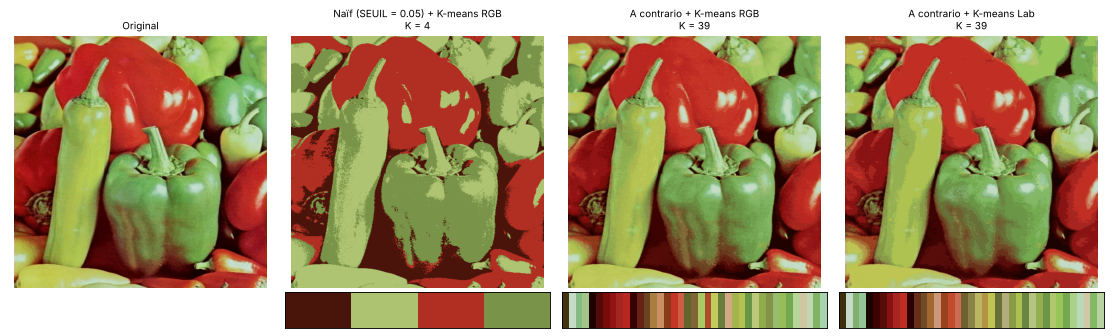

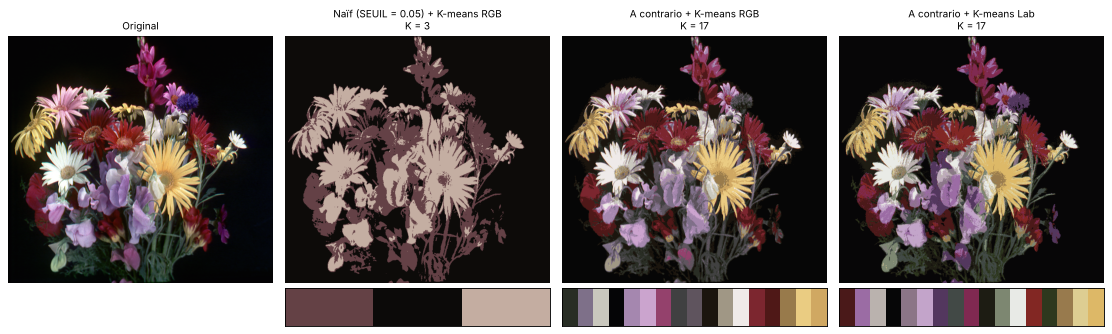

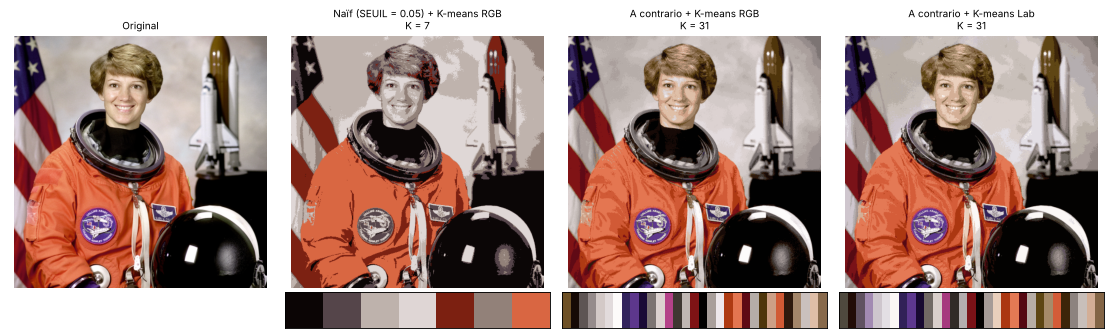

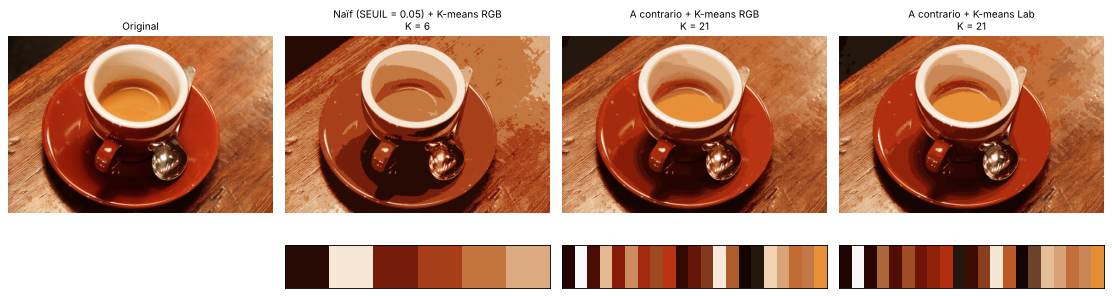

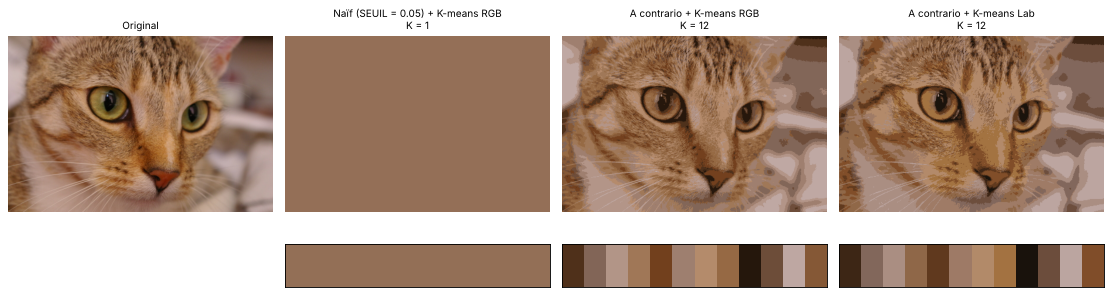

In [11]:
import demo_resultats
for chemin in demo_resultats.IMAGES:
    demo_resultats.afficher_resultats(chemin, enregistrer=False)
    plt.show()

**Observations**
- **Version a contrario :** le nombre de couleurs s'adapte au contenu. On obtient $K=12$ pour le chat, dont les couleurs sont peu variées, et jusqu'à $K=39$ pour les poivrons. Les images finales restent très proches des originales.
- **Petits détails :** les détails de couleur vive sont conservés. Par exemple, le bleu du drapeau et l'écusson violet de l'astronaute, ou les fleurs violettes.
- **Version naïve :** le seuil de $5\,\%$ est beaucoup trop permissif pour ces grandes images. Le chat est réduit à une seule couleur ($K=1$), la fleur à 3 couleurs, et le bleu du drapeau disparaît. C'est le défaut déjà vu au §4.3 : le seuil ne tient pas compte du nombre de pixels.
- **RGB ou Lab :** la différence est peu visible à l'oeil sur ces photos. Elle apparaît surtout dans les mesures du §4.2 (meilleur $\Delta E$ en Lab, meilleur PSNR en RGB).

## 5. Analyse critique

**Points forts constatés**
- **$K$ est trouvé automatiquement.** Les valeurs obtenues (17 pour la fleur, 39 pour les poivrons) sont du même ordre que celles de l'article (« usually less than 30 »).
- **Les petites zones de couleur sont conservées** (§4.1 et §4.2). C'est l'apport principal par rapport au median cut, à la popularité et à K-means, et c'est mesurable avec le $\Delta E$ sur la zone.
- **Le test a contrario a un seul paramètre, peu sensible**, alors que notre version naïve dépend fortement de son seuil.
- **Le temps de calcul reste raisonnable** : quelques secondes en Python pour une image $512\times512$.

**Limites et difficultés**
- **Sensibilité à la quantification et à la compression.** Le test devient très sévère quand $N$ est grand : il détecte toute structure fine des histogrammes, y compris des artefacts. Sur `Poivrons.jpeg`, cela donne trop de modes de teinte (9) et trop de couleurs si l'on ne regroupe pas les classes de S et I. La segmentation trouve des modes « statistiquement significatifs », ce qui n'est pas toujours la même chose que « perceptuellement différents ». Notre choix de largeur 4 est un réglage qui réintroduit un peu d'arbitraire.
- **Graines presque vides.** Certains groupes finaux contiennent moins de 50 pixels. Ils donnent des couleurs de la palette presque inutiles. Une fusion des couleurs très proches dans Lab après K-means (ou la nomination des couleurs du §5 de l'article) réduirait $K$.
- **Erreur quadratique.** ACoPa ne minimise pas l'erreur quadratique. À $K$ égal, son PSNR est comparable à celui de K-means mais pas meilleur, surtout en Lab. Le choix entre RGB et Lab dépend de l'objectif : fidélité moyenne ou couleurs perçues.
- **La hiérarchie H → S → I** fait confiance à la teinte. Deux couleurs de même teinte et d'intensités proches mais de saturations différentes sont séparées, alors que deux teintes voisines dans un mode large sont confondues avant d'avoir vu S et I.

**Écarts avec l'article et ce que nous n'avons pas fait**
- Borne de Hoeffding au lieu de la queue binomiale exacte, et seulement 3 positions de pic testées (§3.4).
- Coupure du cercle de teinte au minimum de l'histogramme (§3.5).
- Nous n'avons pas comparé avec Mean-Shift, ni implémenté la nomination des couleurs (dictionnaires X11 et NBS/ISCC, §5 de l'article), faute de temps.
- Nous n'avons pas les images de l'article (Ladybug, Olive tree). L'image synthétique « coccinelle » et les fleurs violettes jouent le même rôle.

**Pistes**
- Utiliser la queue binomiale exacte (`scipy.stats.binom`) et tester tous les pics $c$.
- Fusionner les couleurs de la palette dont le $\Delta E$ est inférieur à un seuil perceptif (par exemple 5).
- Compléter la comparaison avec Mean-Shift.

## 6. Utilisation des agents conversationnels

Nous avons utilisé **Claude** (Anthropic), sur claude.ai, tout au long du projet. Voici en détail à quoi il nous a servi, et comment nous avons vérifié ce qu'il produisait.

**Compréhension de l'article.** Claude a traduit l'article en français. Nous lui avons ensuite posé des questions sur les points difficiles : l'estimateur de Grenander, l'algorithme Pool Adjacent Violators, la différence entre « unimodal » au sens strict et « unimodal au sens d'un test », le rôle de l'algorithme FTC, et ce que fait le test a contrario de la référence [10]. Par exemple, nous avons demandé si le test d'unimodalité revenait à « détecter une croissance puis une décroissance autour d'un pic ». Claude a expliqué que c'est bien l'idée, mais que la croissance et la décroissance sont jugées par rapport à l'estimateur de Grenander, et non vérifiées de façon stricte.

**Écriture du code.** Le code de `segmentation_naive.py` et de `segmentation_auto.py`, ainsi que le code de ce notebook, ont été écrits par Claude à partir de nos demandes, étape par étape. Nous avons d'abord fait HSI et PAV, puis le test à seuil fixé à la main (que nous avions choisi pour commencer simplement), puis l'affichage des histogrammes et de leur approximation, puis le FTC, puis le test a contrario. Le median cut (`median_cut.py`) a aussi été écrit avec son aide. Claude a enfin réorganisé le dépôt et corrigé les imports cassés entre nos scripts. Le README précise fichier par fichier qui a écrit quoi.

**Vérification.** Nous n'avons pas pris le code tel quel :
- tests sur des cas connus : l'exemple $(5,3,4,2)$ de l'annexe B pour PAV, et les teintes des couleurs pures pour HSI ;
- histogrammes synthétiques à une et deux bosses (§3.3) ;
- inspection visuelle des histogrammes et des segmentations sur nos images ;
- relecture du code ligne à ligne pour pouvoir l'expliquer.

Ces vérifications ont fait apparaître le problème des histogrammes « en peigne » des poivrons (§4.3).

**Rédaction.** Claude nous a aidés à rédiger le compte rendu d'avancement d'octobre et la structure de ce rapport. Les interprétations des résultats ont été discutées et relues par nous.

**Limites rencontrées.** L'agent n'a pas pu lire de façon fiable la formule exacte du test dans la référence [10] (texte du PDF mal extrait). La forme utilisée (borne de Hoeffding) est donc une reconstruction, signalée comme telle au §3.4. De façon générale, l'agent produit du code qui « a l'air juste ». Seuls les tests et les figures permettent de vérifier qu'il l'est. Nous avons aussi dû insister pour obtenir un code simple, que nous pouvons expliquer à l'oral.

*[À compléter par Hugo : son utilisation des agents conversationnels pour K-means, la popularité et la comparaison.]*

## 7. Répartition du travail et références

| Partie | Qui |
|---|---|
| K-means naïf puis vectorisé, popularité, script de comparaison, première version heuristique d'ACoPa (`acopa_simple.py`) | Hugo |
| Median cut, compte rendu d'avancement, segmentation (versions naïve et automatique), expériences et rapport | Aziz, avec Claude pour l'écriture du code (voir §6) |

**Références**
1. J. Delon, A. Desolneux, J.-L. Lisani, A.-B. Petro, *Automatic Color Palette*, Inverse Problems and Imaging, 1(2):265-287, 2007.
2. J. Delon, A. Desolneux, J.-L. Lisani, A.-B. Petro, *A nonparametric approach for histogram segmentation*, IEEE Transactions on Image Processing, 16(1):253-261, 2007 (référence [10] de l'article).
3. A. Desolneux, L. Moisan, J.-M. Morel, *From Gestalt Theory to Image Analysis: A Probabilistic Approach*, Springer, 2008.
4. P. Heckbert, *Color image quantization for frame buffer display*, SIGGRAPH, 1982.